# 05 · Predicción: comparación de modelos y dónde falla cada uno

Validación `GroupKFold` por red (ninguna red en entrenamiento y prueba a la vez).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
TOPO_LABEL = {"erdos_renyi": "Erdős–Rényi", "barabasi_albert": "Barabási–Albert",
              "core_periphery": "Núcleo-periferia"}

In [2]:
from finnet.config import data_dir, models_dir

comp = pd.read_csv(models_dir() / "comparison.csv")
comp.round(4)

,modelo,roc_auc,pr_auc,brier,base_rate,ms_per_prediction,speedup_vs_simulacion,spearman_mean,r2,mae,ms_per_network,network_n,segundos_por_simulacion
0,logistic_collapse,0.9575,0.7413,0.0834,0.1112,0.1632,481.8140,NaN,NaN,NaN,NaN,NaN,0.0786
1,xgb_collapse,0.9800,0.8796,0.0378,0.1112,0.1807,435.0290,NaN,NaN,NaN,NaN,NaN,0.0786
2,xgb_nodes,NaN,NaN,NaN,NaN,NaN,21743.3990,0.2958,0.5039,0.0881,0.4520,125.0,0.0786
3,gcn_nodes,NaN,NaN,NaN,NaN,NaN,14837.5189,0.2938,0.5966,0.0754,0.6624,125.0,0.0786


## Colapso global: XGBoost contra logística, por rango de R y topología
Predicciones fuera de pliegue recalculadas aquí con la misma configuración.

/Users/ofi/Documents/Universidad/finnet/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,logística,XGBoost
grupo,,
"(0.0, 0.8]",0.968,0.977
"(0.8, 0.95]",0.967,0.982
"(0.95, 1.05]",0.971,0.978
"(1.05, 1.2]",0.961,0.982
"(1.2, 2.0]",0.925,0.974
ER,0.952,0.973
BA,0.959,0.986
NP,0.956,0.981


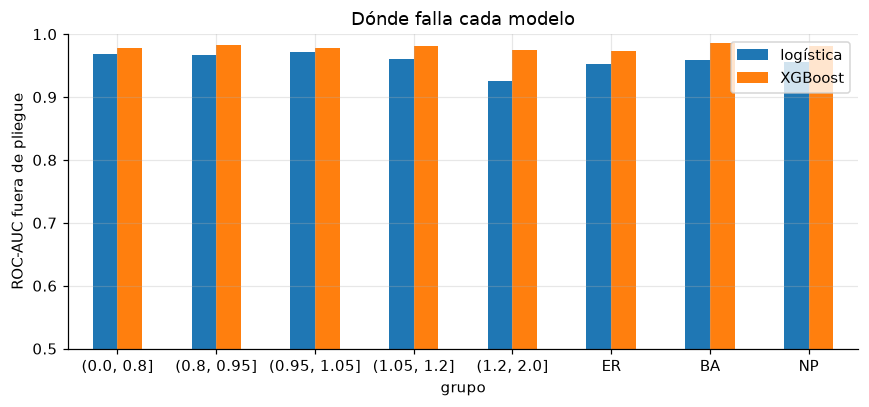

In [3]:
from sklearn.metrics import roc_auc_score
from finnet.config import load_config
from finnet.experiments import SCENARIO_FEATURES
from finnet.ml.train import _folds, make_logistic, make_xgb_classifier

cfg = load_config("train.yaml")
esc = pd.read_parquet(data_dir() / "escenarios.parquet")
X = esc[list(SCENARIO_FEATURES)].to_numpy(float); y = esc["collapse"].to_numpy(); g = esc["network_id"].to_numpy()
oof = {"logística": np.zeros(len(y)), "XGBoost": np.zeros(len(y))}
for tr, te in _folds(g, cfg["n_splits"]):
    oof["logística"][te] = make_logistic(cfg).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    oof["XGBoost"][te] = make_xgb_classifier(cfg, y[tr]).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
esc["R_bin"] = pd.cut(esc["R"], [0, 0.8, 0.95, 1.05, 1.2, 2])
topo = {0: "ER", 1: "BA", 2: "NP"}
rows = []
for key, grp in list(esc.groupby("R_bin", observed=True)) + list(esc.groupby("topology")):
    if grp["collapse"].nunique() < 2: continue
    lab = str(key) if not isinstance(key, (int, np.integer)) else topo[int(key)]
    rows.append({"grupo": lab, **{m: roc_auc_score(grp["collapse"], p[grp.index]) for m, p in oof.items()}})
fails = pd.DataFrame(rows).set_index("grupo")
fig, ax = plt.subplots(figsize=(8, 3.8))
fails.plot.bar(ax=ax, rot=0); ax.set(ylabel="ROC-AUC fuera de pliegue", ylim=(0.5, 1), title="Dónde falla cada modelo")
fig.tight_layout(); fig.savefig(FIG / "fase6_comparacion_modelos.png")
fails.round(3)

## Calibración

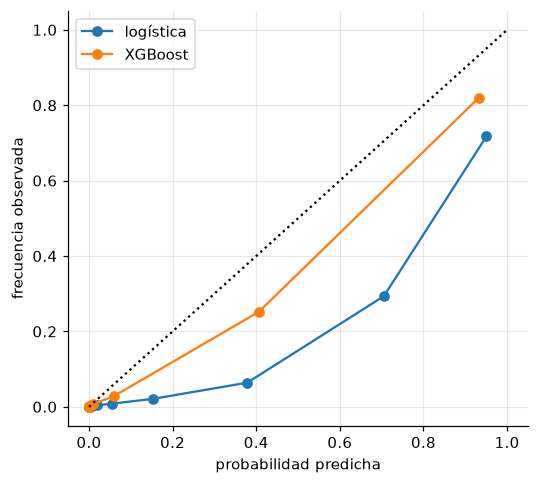

In [4]:
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(5, 4.5))
for m, p in oof.items():
    fy, fx = calibration_curve(y, p, n_bins=10, strategy="quantile")
    ax.plot(fx, fy, "o-", label=m)
ax.plot([0, 1], [0, 1], "k:"); ax.set(xlabel="probabilidad predicha", ylabel="frecuencia observada"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fase6_calibracion.png")

## Importancia de variables (SHAP, XGBoost de colapso)

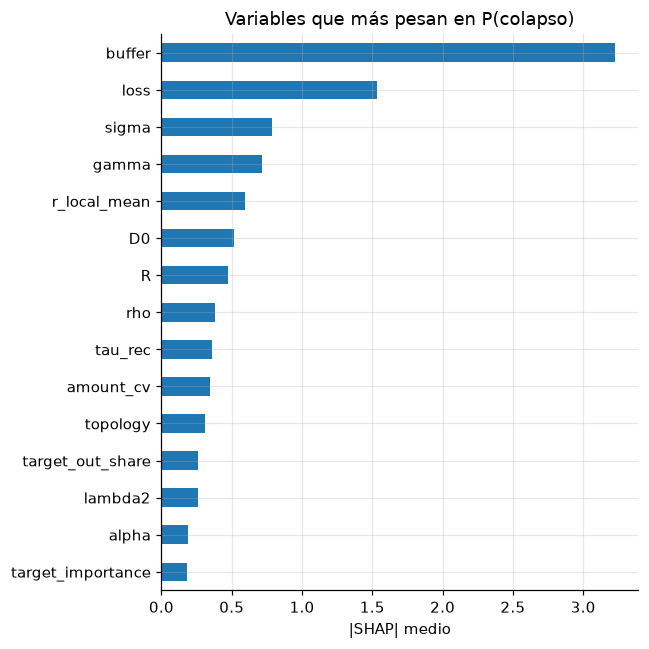

In [5]:
import shap
from finnet.ml.registry import load_model
model, meta, _ = load_model(models_dir(), "xgb_collapse")
sample = esc[list(SCENARIO_FEATURES)].sample(2000, random_state=0)
sv = shap.TreeExplainer(model).shap_values(sample.to_numpy(float))
imp = pd.Series(np.abs(sv).mean(0), index=SCENARIO_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6, 6)); imp.tail(15).plot.barh(ax=ax)
ax.set(xlabel="|SHAP| medio", title="Variables que más pesan en P(colapso)")
fig.tight_layout(); fig.savefig(FIG / "fase6_shap_colapso.png")